# Quantile balancing: giving every expert an equal share by choosing thresholds

*Jianlin Su, "MoE World Tour" blog series, parts 6 and 7 (Feb 2026; an [English translation of part 7](https://rohin-garg.github.io/kexue-en/translations/translation_11626.html) is the source we worked from). Marin Mochi (Open Athena) is the follower shown in the diagram this series is based on. Notebook 8 of 9 in the "How LLMs build on each other" series.*

**A note on sources.** Unlike the other notebooks in this series, this one is based on a **blog post, not a paper**. There are therefore no paper figures to show, and no large-scale experiments to quote; every figure below is ours. We checked the mathematics numerically, and we did not verify claims about which production model uses it.

**TL;DR.** In a mixture-of-experts layer each token picks its experts by router score. Left alone, a few experts get most of the tokens and the rest idle. Earlier fixes either add a **loss** that pushes towards balance (which also pushes on the gradients of the model) or, as in DeepSeek-V3 (notebook 3 of that series), nudge a **per-expert bias** up or down by a fixed step according to whether the expert is over- or under-loaded. Su's observation: balancing is an *assignment problem* with a clean solution. Write down "give each expert exactly its fair share of the tokens, with the best total score", take its Lagrangian dual, and the per-expert multipliers $\beta_j$ turn out to be simply the **$(1-k/n)$ quantile of expert $j$'s scores**. Use $\beta_j$ as a threshold: a token activates expert $j$ when its score exceeds $\beta_j$. In a streaming setting, track each quantile with a running average. The bias method is then an iterative way to find the same $\beta$.

We derive that, verify the derivation numerically, check that DeepSeek's sign-update rule is stochastic gradient descent on the same dual (up to a sign), and compare the three approaches on a drifting synthetic router and on a small language model.

| step | what we do |
|---|---|
| 1 | the balancing problem, stated as an optimisation |
| 2 | the dual: why the multiplier is a quantile (derivation, verified) |
| 3 | using the quantile as a threshold: what changes about top-$k$ |
| 4 | running it online: moving-average quantile, and its initial value |
| 5 | the sign-update rule is the same dual: DeepSeek's bias, derived |
| 6 | experiment: a router whose preferences drift |
| 7 | experiment: a small language model with three balancing rules |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. The problem

Take a batch of $m$ tokens and $n$ experts. The router gives a score $s_{ij}$ for token $i$ and expert $j$ (higher means better match). Each token should be sent to $k$ experts. Without any constraint, send each token to its $k$ highest scores: best total score, but the loads $\sum_i x_{ij}$ can be wildly uneven.

Add the constraint that every expert gets the same share. Total assignments are $mk$, so each expert should get $mk/n$:

$$ \max_{x_{ij}\in\{0,1\}}\ \sum_{i,j} x_{ij}\,s_{ij} \qquad\text{subject to}\qquad \sum_i x_{ij} = \frac{mk}{n}\ \ \text{for every expert } j . $$

(The blog solves this simplified version, which does **not** also force each token to get exactly $k$ experts; we return to that in section 3.) This asks for the best-scoring assignment that is exactly balanced. We cannot afford an integer program on every batch, but the dual is easy.

## 2. The dual: the multiplier is a quantile

Relax $x_{ij}\in\{0,1\}$ to $x_{ij}\in[0,1]$ and attach one Lagrange multiplier $\beta_j$ to each expert's load constraint. The dual problem is

$$ \min_{\beta}\ \ \max_{x\in[0,1]}\ \sum_{i,j} x_{ij}\,(s_{ij}-\beta_j) + \frac{mk}{n}\sum_j\beta_j . $$

Fix $\beta$. The inner maximum is trivial: set $x_{ij}=1$ if $s_{ij}-\beta_j>0$ and $0$ otherwise. So **the optimal rule is a threshold on a shifted score**, not a top-$k$ sort. Substituting back, the dual separates into one problem per expert (drop the subscript $j$):

$$ g(\beta)=\frac{mk}{n}\,\beta+\sum_{i}\max(0,\ s_i-\beta) . $$

The sum counts how much each score exceeds $\beta$. It is convex and piecewise linear in $\beta$. Its slope at $\beta$ is $\frac{mk}{n}-\#\{i: s_i>\beta\}$: negative while *more* than $mk/n$ tokens are above $\beta$, positive once fewer are. The minimum is at the point where exactly $mk/n$ scores lie above $\beta$, which is the **$(mk/n+1)$-th largest score**, that is the $(1-k/n)$ quantile of the expert's scores.

We check each step. First, minimising $g$ by brute force gives the quantile:

In [2]:
torch.manual_seed(0)
m, n, k = 2000, 16, 4
s = torch.randn(m, n) + torch.linspace(-1, 1, n)                 # expert scores with different popularity
j = 3
sj = s[:, j]
g = lambda beta: (m * k / n) * beta + (sj - beta).clamp_min(0).sum()
grid = torch.linspace(sj.min().item(), sj.max().item(), 4001)
beta_brute = grid[torch.stack([g(b) for b in grid]).argmin()]
beta_q = A.quantile_offsets(s, k)[j]
print(f"expert {j}: brute-force minimiser of the dual = {beta_brute:.3f}; the (1 - k/n) quantile = {beta_q:.3f}")
check("minimising the dual by brute force gives the (1 - k/n) quantile", abs(beta_brute - beta_q) < 0.02)

expert 3: brute-force minimiser of the dual = 0.105; the (1 - k/n) quantile = 0.104
PASS - minimising the dual by brute force gives the (1 - k/n) quantile 


Second, the thresholds give **exact balance**: with $\beta_j$ the quantile, expert $j$ is activated for exactly $mk/n$ tokens, for every expert at once, however unequal the experts' score distributions are:

In [3]:
class SwiGLU(nn.Module):
    def __init__(self, d, f):
        super().__init__()
        self.w1, self.w3, self.w2 = nn.Linear(d, f, bias=False), nn.Linear(d, f, bias=False), nn.Linear(f, d, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class MoE(nn.Module):
    """Routed mixture of experts.
    latent=None : ordinary MoE, experts live in the model width d.
    latent=l    : LatentMoE.  The router still reads the full d-wide token, but the token is first projected
                  d -> l, ALL experts run in width l, and the mixed result is projected l -> d.
    bias        : per-expert selection bias (used for choosing experts only, never for the gate value)."""
    def __init__(self, d, n_experts, topk, f, latent=None, n_shared=0, f_shared=None):
        super().__init__()
        self.d, self.E, self.k = d, n_experts, topk
        w = latent or d
        self.latent = latent
        if latent:
            self.down, self.up = nn.Linear(d, latent, bias=False), nn.Linear(latent, d, bias=False)
        self.router = nn.Linear(d, n_experts, bias=False)
        self.experts = nn.ModuleList([SwiGLU(w, f) for _ in range(n_experts)])
        self.shared = SwiGLU(d, f_shared or f) if n_shared else None
        self.register_buffer("bias", torch.zeros(n_experts))
        self.load = torch.zeros(n_experts)

    def route(self, x, bias=None):
        aff = torch.sigmoid(self.router(x))                         # [N,E]
        sel = (aff + (self.bias if bias is None else bias)).topk(self.k, -1).indices
        g = aff.gather(-1, sel)
        return sel, g / g.sum(-1, keepdim=True)

    def forward(self, x):
        shp = x.shape
        x = x.reshape(-1, shp[-1])
        sel, gate = self.route(x)
        z = self.down(x) if self.latent else x
        out = torch.zeros_like(z)
        for e in range(self.E):
            tok, slot = (sel == e).nonzero(as_tuple=True)
            if tok.numel():
                out.index_add_(0, tok, gate[tok, slot, None] * self.experts[e](z[tok]))
        out = self.up(out) if self.latent else out
        if self.shared is not None:
            out = out + self.shared(x)
        self.load = torch.bincount(sel.flatten(), minlength=self.E).float() / sel.numel()
        return out.view(shp)


def max_violation(load):
    """MaxVio = (max load - mean load) / mean load  (0 = perfectly balanced)."""
    return float((load.max() - load.mean()) / load.mean())


def quantile_offsets(scores, k):
    """Quantile balancing, exact one-shot version.  scores [m,n] (m tokens, n experts).
    Expert j gets the offset beta_j = the (m*k/n + 1)-th largest score in its column, i.e. the (1-k/n) quantile.
    An expert is switched on for a token when score - beta_j > 0 (a sign test, not a top-k sort), so
    every expert is on for ~ m*k/n tokens and the number of experts per token floats around k."""
    m, n = scores.shape
    r = int(round(m * k / n))
    return scores.sort(dim=0, descending=True).values[r]


def quantile_init(sigma, k, n):
    """beta_init = sigma * Phi^-1(1 - k/n) for logits assumed ~ N(0, sigma^2)."""
    return sigma * torch.distributions.Normal(0.0, 1.0).icdf(torch.tensor(1 - k / n)).item()

In [4]:
beta = A.quantile_offsets(s, k)
active = (s - beta) > 0
count = active.sum(0)
print("tokens activating each expert (target m k / n =", m * k // n, "):", count.tolist())
print("experts per token: mean", round(active.sum(1).float().mean().item(), 3), ", min", active.sum(1).min().item(), ", max", active.sum(1).max().item())
print("same scores, plain top-k: tokens per expert", torch.bincount(s.topk(k, -1).indices.flatten(), minlength=n).tolist())
check("every expert is activated for m*k/n tokens (+-1) when beta is the quantile", (count - m * k // n).abs().max() <= 1)
check("balance is exact even though the experts' score distributions are very different", A.max_violation(count.float()) < 0.01)
check("the average number of experts per token is k", abs(active.sum(1).float().mean().item() - k) < 0.01)

tokens activating each expert (target m k / n = 500 ): [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
experts per token: mean 4.0 , min 0 , max 10
same scores, plain top-k: tokens per expert [79, 93, 142, 154, 204, 238, 303, 388, 434, 554, 606, 736, 851, 955, 1051, 1212]
PASS - every expert is activated for m*k/n tokens (+-1) when beta is the quantile 
PASS - balance is exact even though the experts' score distributions are very different 
PASS - the average number of experts per token is k 


## 3. What changes about top-$k$

Two differences from the usual router, both visible above.

**Threshold instead of sort.** A token activates *every* expert whose score exceeds that expert's $\beta_j$. The **number of experts per token is no longer fixed at $k$**: on average it is $k$, but some tokens activate fewer and some more. The blog frames this as *dynamic activation*: tokens that look relevant to many experts get many, "easy" tokens get few. If you want exactly $k$ per token you can still use the offsets inside a top-$k$ (select the top $k$ of $s_{ij}-\beta_j$); the thresholds are then a bias, which is exactly the kind of bias DeepSeek uses, but balance is no longer exact (the second constraint also binds).

**Offsets are computed from the scores, not learned by gradient.** There is no extra loss term and no hyperparameter beyond the averaging constant below, and no gradient flows through $\beta$. The router scores themselves still get gradient through the gate weights of the selected experts, exactly as before.

## 4. Running it online

In training we only ever see a batch at a time, and the exact quantile of one batch is a noisy estimate of the quantile of the whole stream. A threshold fitted to batch $t$ and applied to batch $t+1$ is not exactly balanced. The blog's remedy is a moving average. At each step: (1) **first** decide the activations with the current $\beta$, (2) **then** update with the new batch's quantile,

$$ \beta\leftarrow\lambda\,\beta+(1-\lambda)\,\mathrm{quantile}_{1-k/n}\big(s_{:,j}\big)\qquad(\lambda=0.9 \text{ in the blog}), $$

in that order so that the activation of a token never depends on its own score (no leak of the current batch into its own decision).

**Initial value.** At the start of training there is no history. If the router logits are roughly $\mathcal N(0,\sigma^2)$, the $(1-k/n)$ quantile has a closed form, $\beta_{init}=\sigma\,\Phi^{-1}(1-k/n)$, with $\Phi^{-1}$ the standard normal inverse CDF. For an RMS-normalised input of width $d$ and weights of standard deviation $\tilde\sigma$, the logit scale is about $\sigma\approx\tilde\sigma\sqrt d$. For a monotone activation like sigmoid, apply the activation to $\beta_{init}$. We check the closed form against the empirical quantile:

In [5]:
torch.manual_seed(1)
d_, n_, k_ = 256, 16, 2
Wr = torch.randn(n_, d_) * 0.02                                    # router weights, std 0.02
x = F.normalize(torch.randn(20000, d_), dim=-1) * math.sqrt(d_)    # RMS-normalised tokens (RMS = 1)
logits = x @ Wr.T
sigma_pred = 0.02 * math.sqrt(d_)
beta_formula = A.quantile_init(sigma_pred, k_, n_)
beta_emp = logits.flatten().quantile(1 - k_ / n_).item()
print(f"predicted sigma {sigma_pred:.3f}, measured {logits.std():.3f}")
print(f"beta_init: closed form {beta_formula:.3f}, empirical quantile {beta_emp:.3f}")
check("the closed-form initial offset matches the empirical (1 - k/n) quantile of the logits", abs(beta_formula - beta_emp) < 0.02)

predicted sigma 0.320, measured 0.322
beta_init: closed form 0.368, empirical quantile 0.370
PASS - the closed-form initial offset matches the empirical (1 - k/n) quantile of the logits 


## 5. The bias rule of DeepSeek-V3 is the same dual, solved by sign steps

The blog also offers a gradient alternative for the dual. The derivative of $g$ with respect to $\beta_j$ is $\frac{mk}{n}-\#\{i:s_{ij}>\beta_j\}$: the target load minus the current load. Replace the exact quantile with a **sign step** of size $\gamma$:

$$ \beta_j\leftarrow\beta_j-\gamma\,\mathrm{sign}\Big(\frac{mk}{n}-\mathrm{load}_j\Big) \quad\Longleftrightarrow\quad b_j\leftarrow b_j+\gamma\,\mathrm{sign}\big(\mathrm{target}-\mathrm{load}_j\big),\ \ b_j=-\beta_j . $$

The second form is DeepSeek-V3's **auxiliary-loss-free** rule: an expert that received less than its share gets a bias increase of $\gamma$, one that received more gets a decrease. DeepSeek adds the bias to the score for choosing the top-$k$; the dual adds it as a threshold. The update is the same. Numerically, run both on the same stream and compare $\beta$ against $-b$ (the two differ only in how the load is counted, so we count the load the same way in both here):

In [6]:
torch.manual_seed(2)
n_, k_, m_, gam = 8, 2, 400, 0.01
pop = torch.randn(n_) * 0.5
b_ds = torch.zeros(n_)                  # DeepSeek form: bias added to the score
beta = torch.zeros(n_)                  # dual: threshold
max_diff = 0.0
for step in range(200):
    sc = torch.sigmoid(pop + torch.randn(m_, n_))
    target = m_ * k_ / n_
    load_dual = ((sc - beta) > 0).float().sum(0)                  # dual: expert j is on when score > beta_j
    beta = beta - gam * torch.sign(target - load_dual)
    load_ds = ((sc + b_ds) > 0).float().sum(0)                    # DeepSeek form: expert j is on when score + b_j > 0
    b_ds = b_ds + gam * torch.sign(target - load_ds)
    max_diff = max(max_diff, (beta + b_ds).abs().max().item())
print("largest |beta + b| over 200 steps:", max_diff)
check("the sign-step dual update and DeepSeek's bias update produce the same sequence (beta = -b)", max_diff < 1e-6)

largest |beta + b| over 200 steps: 0.0
PASS - the sign-step dual update and DeepSeek's bias update produce the same sequence (beta = -b) 


(The two updates are written differently in code, a threshold subtracted versus a bias added, and coincide because the algebra is the same; this is a check that our sign conventions are right, not an independent experiment.) The practical difference between the methods is therefore **how $\beta$ is moved**: DeepSeek takes small fixed steps and so converges gradually and keeps a bias that wobbles by $\pm\gamma$; the quantile jumps straight to the current batch's balance point (smoothed by $\lambda$). Which is better depends on how fast the score distributions change, which is what the next experiment probes.

## 6. Experiment: a router whose preferences drift

A synthetic stream of router scores for $n=16$ experts, $k=2$, 512 tokens per step. Each expert has a "popularity" offset (some experts' scores are higher on average), scores are the sigmoid of popularity plus noise. At step 150 the popularities are **reshuffled**, the way a router's preferences change as the model trains. We run four rules on the same stream and plot **MaxVio**, the overload of the busiest expert relative to the mean load, $(\max_j \mathrm{load}_j-\overline{\mathrm{load}})/\overline{\mathrm{load}}$ (0 means perfectly balanced), step by step:

1. **none**: plain top-$k$.
2. **DeepSeek bias**: top-$k$ on $s+b$, with the sign update, $\gamma=0.01$.
3. **QB, moving average** ($\lambda=0.9$), threshold selection, initialised with the Gaussian formula.
4. **QB, previous batch's exact quantile** ($\lambda=0$), to show what the moving average buys.

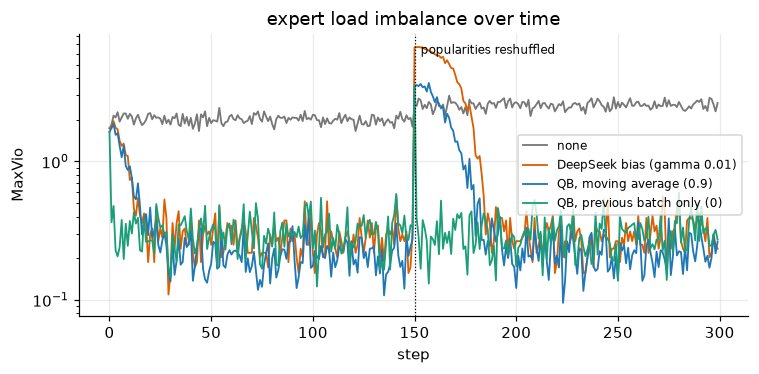

rule                            mean MaxVio steps 100-150  steps to < 0.25 after start  after the shuffle
none                                                1.983                         None               None
DeepSeek bias (gamma 0.01)                          0.282                           19                 38
QB, moving average (0.9)                            0.212                           24                 35
QB, previous batch only (0)                         0.306                            3                  3
PASS - every balancing rule cuts the steady-state MaxVio to under a fifth of the unbalanced value 
PASS - the moving average steadies the quantile rule (lower MaxVio than the previous-batch-only version) 


In [7]:
n, k, m, steps, drift_at = 16, 2, 512, 300, 150

def make_stream(seed):
    g = torch.Generator().manual_seed(seed)
    pops = [torch.randn(n, generator=g) * 0.8, torch.randn(n, generator=g) * 0.8]
    for t in range(steps):
        pop = pops[0] if t < drift_at else pops[1]
        yield torch.sigmoid(pop + torch.randn(m, n, generator=g))

def run_rule(rule, seed=0, gamma=0.01, lam=0.9):
    b = torch.zeros(n)                       # DeepSeek bias
    beta = torch.full((n,), float(torch.sigmoid(torch.tensor(A.quantile_init(1.0, k, n)))))   # Gaussian init, applied through the sigmoid
    mv = []
    for sc in make_stream(seed):
        if rule == "none":
            sel = sc.topk(k, -1).indices; cnt = torch.bincount(sel.flatten(), minlength=n).float()
        elif rule == "deepseek":
            sel = (sc + b).topk(k, -1).indices; cnt = torch.bincount(sel.flatten(), minlength=n).float()
            b = b + gamma * torch.sign(cnt.mean() - cnt)
        else:                                 # quantile balancing: threshold, then update the threshold with this batch
            cnt = ((sc - beta) > 0).float().sum(0)
            beta = lam * beta + (1 - lam) * sc.quantile(1 - k / n, dim=0)
        mv.append(A.max_violation(cnt))
    return np.array(mv)

curves = {
    "none": run_rule("none"),
    "DeepSeek bias (gamma 0.01)": run_rule("deepseek"),
    "QB, moving average (0.9)": run_rule("qb", lam=0.9),
    "QB, previous batch only (0)": run_rule("qb", lam=0.0),
}
fig, ax = plt.subplots(figsize=(7.0, 3.5))
for (name, v), c in zip(curves.items(), [C["grey"], C["orange"], C["blue"], C["green"]]):
    ax.plot(v, label=name, color=c, lw=1.2)
ax.axvline(drift_at, color="k", ls=":", lw=.8); ax.text(drift_at + 3, ax.get_ylim()[1] * .85, "popularities reshuffled", fontsize=8)
ax.set_xlabel("step"); ax.set_ylabel("MaxVio"); ax.set_yscale("log"); ax.legend(fontsize=8); ax.set_title("expert load imbalance over time"); plt.tight_layout(); plt.show()

def recover(v, start, thr=0.25):
    idx = np.where(v[start:] < thr)[0]
    return int(idx[0]) if len(idx) else None
print(f"{'rule':30s} {'mean MaxVio steps 100-150':>26s} {'steps to < 0.25 after start':>28s} {'after the shuffle':>18s}")
for name, v in curves.items():
    print(f"{name:30s} {v[100:150].mean():26.3f} {str(recover(v, 0)):>28s} {str(recover(v, drift_at)):>18s}")
check("every balancing rule cuts the steady-state MaxVio to under a fifth of the unbalanced value",
      all(curves[k_][100:150].mean() < 0.2 * curves["none"][100:150].mean() for k_ in list(curves)[1:]))
check("the moving average steadies the quantile rule (lower MaxVio than the previous-batch-only version)",
      curves["QB, moving average (0.9)"][100:150].mean() < curves["QB, previous batch only (0)"][100:150].mean())

**Result (one seed of the stream; the plot and table above).** Without balancing the busiest expert gets about three times its fair share (MaxVio about 2). All three balancing rules bring it down to between 0.2 and 0.3. DeepSeek's bias reaches MaxVio below 0.25 after 19 steps and, after the reshuffle, in 38 steps; quantile balancing with the moving average takes 24 and 35 steps; **the previous batch's exact quantile takes 3 steps both times but is noisier** (0.31 on average against 0.21): a threshold fitted to one batch is not exactly right for the next, as section 4 said, and the average trades speed for steadiness. DeepSeek's step size $\gamma$ plays the same role (larger is faster and wobblier). A **floor** of about 0.2 comes from sampling noise alone: with 512 tokens and 16 experts each expert's count is about $64\pm8$, and the largest of 16 such counts is typically two standard deviations above the mean, so none of these curves can go much below it. (This is our estimate of the floor, not something we measured separately.) The differences between the bias rule and the moving-average quantile (0.28 against 0.21; 38 against 35 steps) are within what one run of one stream can distinguish, so we do not claim either is better. What the simulation shows is that both work, and each has one knob that moves between fast-and-noisy and slow-and-steady.

## 7. Experiment: a small language model with three balancing rules

The synthetic stream has no model in it. To see the rules inside training we use the same small language model as in the LatentMoE notebook: 4 layers of width 64, every feed-forward layer a mixture of 16 experts (width 64, intermediate width 16) with one shared expert, character-level text. Three routers:

1. **top-$k$, no balancing**, $k=2$.
2. **DeepSeek bias**: top-$k$ on $s+b$, $b$ updated each step from the observed loads, $\gamma=0.005$. (The kit's `MoE` already supports the `bias` argument for selection only.)
3. **quantile balancing**: threshold selection `score > beta`, gate weights normalised over the activated experts, $\beta$ updated by the moving-average quantile ($\lambda=0.9$) after each step; initialised from the Gaussian formula using the first batch's logit scale. A token that activates no expert gets only the shared expert's output.

For all three the gate value is the affinity of the selected experts, normalised over the selected set; the bias or threshold is used for *selection only*, as in notebook 3 of the DeepSeek series.

In [8]:
data = A.CharData()
Dm, Hh, NL, NE, KK = 64, 4, 4, 16, 2

class QBMoE(A.MoE):
    """Quantile-balanced MoE layer: expert j is active for a token when sigmoid-affinity > beta_j."""
    def __init__(self, *a, lam=0.9, **kw):
        super().__init__(*a, **kw)
        self.lam, self.initialised = lam, False
        self.register_buffer("beta", torch.zeros(self.E))
        self.n_active = 0.0

    def forward(self, x):
        shp = x.shape
        xf = x.reshape(-1, shp[-1])
        logits = self.router(xf)
        aff = torch.sigmoid(logits)
        if not self.initialised:                                                 # Gaussian initial offset from the logit scale
            sigma = logits.detach().std().item()
            self.beta.fill_(float(torch.sigmoid(torch.tensor(A.quantile_init(sigma, self.k, self.E)))))
            self.initialised = True
        active = (aff.detach() - self.beta) > 0                                    # decide with the OLD beta
        w = aff * active
        gate = w / w.sum(-1, keepdim=True).clamp_min(1e-9)                         # normalise over the activated experts
        out = torch.zeros_like(xf)
        for e in range(self.E):
            tok = active[:, e].nonzero(as_tuple=True)[0]
            if tok.numel():
                out.index_add_(0, tok, gate[tok, e, None] * self.experts[e](xf[tok]))
        if self.shared is not None:
            out = out + self.shared(xf)
        cnt = active.float().sum(0)
        self.load = cnt / cnt.sum().clamp_min(1)
        self.n_active = active.float().sum(-1).mean().item()
        with torch.no_grad():                                                      # then update beta with this batch
            q = aff.detach().quantile(1 - self.k / self.E, dim=0)
            self.beta.mul_(self.lam).add_((1 - self.lam) * q)
        return out.view(shp)

def build(rule, seed):
    torch.manual_seed(seed)
    if rule == "QB":
        mk = lambda: QBMoE(Dm, NE, KK, 16, n_shared=1, f_shared=32)
    else:
        mk = lambda: A.MoE(Dm, NE, KK, 16, n_shared=1, f_shared=32)
    return A.MiniLM(data.vocab, Dm, lambda i: A.Attn(Dm, Hh), lambda i: mk(), n_layers=NL)

def train_balance(rule, seed, steps=400, gamma=0.005):
    model = build(rule, seed)
    log = []
    def hook(s, m, seq):
        if rule == "deepseek":
            for b in m.blocks:
                load = b.ffn.load
                b.ffn.bias += gamma * torch.sign(load.mean() - load)               # sign update on the bias, selection-only
        log.append(float(np.mean([A.max_violation(b.ffn.load) for b in m.blocks])))
        return 0.0
    A.train_lm(model, data, steps=steps, B=32, T=64, lr=3e-3, seed=seed, hook=hook)
    return model, np.array(log), A.evaluate(model, data)

rules = ["none", "deepseek", "QB"]
res = {}
t0 = time.time()
for r in rules:
    runs = [train_balance(r, s) for s in [0, 1]]
    res[r] = dict(loss=np.array([x[2] for x in runs]), mv=np.mean([x[1] for x in runs], 0), model=runs[0][0])
    print(f"{r:9s} val loss {res[r]['loss'].mean():.3f} (seeds {np.round(res[r]['loss'], 3)})   MaxVio mean over the last 100 steps {res[r]['mv'][-100:].mean():.3f}   ({time.time() - t0:.0f} s)")

none      val loss 2.492 (seeds [2.508 2.476])   MaxVio mean over the last 100 steps 1.502   (70 s)


deepseek  val loss 2.483 (seeds [2.498 2.468])   MaxVio mean over the last 100 steps 0.182   (155 s)


QB        val loss 2.491 (seeds [2.498 2.483])   MaxVio mean over the last 100 steps 0.181   (255 s)


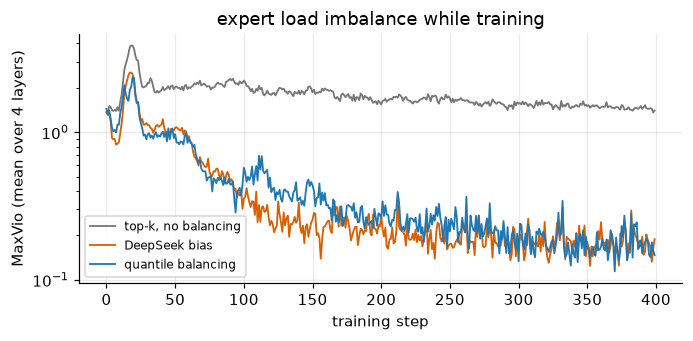

quantile balancing: mean number of experts activated per token, by layer: [1.99, 2.07, 2.02, 2.03] (k = 2)
PASS - both balancing rules cut the training-time MaxVio to under a third of the unbalanced model's 
PASS - no rule changes the validation loss by more than 0.03 (the seed-to-seed spread is of that size) 
PASS - quantile balancing activates about k experts per token on average 


In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for r, c in zip(rules, [C["grey"], C["orange"], C["blue"]]):
    ax.plot(res[r]["mv"], label={"none": "top-k, no balancing", "deepseek": "DeepSeek bias", "QB": "quantile balancing"}[r], color=c, lw=1.2)
ax.set_xlabel("training step"); ax.set_ylabel("MaxVio (mean over 4 layers)"); ax.set_yscale("log"); ax.legend(fontsize=8)
ax.set_title("expert load imbalance while training"); plt.tight_layout(); plt.show()
qb_layers = [b.ffn for b in res["QB"]["model"].blocks]
print("quantile balancing: mean number of experts activated per token, by layer:", [round(l.n_active, 2) for l in qb_layers], f"(k = {KK})")
check("both balancing rules cut the training-time MaxVio to under a third of the unbalanced model's",
      all(res[r]["mv"][-100:].mean() < res["none"]["mv"][-100:].mean() / 3 for r in ["deepseek", "QB"]))
check("no rule changes the validation loss by more than 0.03 (the seed-to-seed spread is of that size)",
      all(abs(res[r]["loss"].mean() - res["none"]["loss"].mean()) < 0.03 for r in ["deepseek", "QB"]))
check("quantile balancing activates about k experts per token on average", all(abs(l.n_active - KK) < 0.3 for l in qb_layers))

**Result (2 seeds, 400 steps).** Without balancing the busiest expert gets about 2.5 times its share (MaxVio 1.5 averaged over the last 100 steps and 4 layers). With DeepSeek's bias it is 0.18, and with quantile balancing 0.18. Validation loss is 2.492 without balancing, 2.483 with the bias and 2.491 with quantile balancing, with a seed-to-seed spread of about 0.02 to 0.03, so **no rule changes the loss measurably here**: balancing makes the experts' loads even but does not make this small model better (it has 16 small experts and trains for 400 steps; this matches what the DeepSeek-V3 notebook on bias-based balancing found). The quantile rule activates 2.0 to 2.07 experts per token on average, so it does hit the target of $k=2$ on average, although individual tokens vary (in the synthetic example of section 2 some tokens activate none and some ten) and that variation did not hurt the loss. Two limits of this experiment: the balancing methods differ in how $\beta$ or $b$ is moved, not in what they converge to, and our training is too short and too small to tell them apart on quality.

## What this notebook did and did not show

**Shown (checks).** The dual of the balanced assignment problem has the $(1-k/n)$ quantile as its solution (verified by brute-force minimisation); thresholding scores at that quantile balances **every** expert exactly (to within one token), whatever the expert's score distribution, with the average number of experts per token equal to $k$; the closed-form Gaussian initial offset matches the empirical quantile; and a sign step on the dual is DeepSeek's bias update with $b=-\beta$. Sections 6 and 7 compare the rules on a drifting synthetic router and in a small language model, with the readings written under each.

**Not shown.** Everything here comes from a blog derivation and from our small experiments. We have no large-scale result, no comparison with an auxiliary loss, and nothing on downstream quality. We did not implement the blog's version for softmax routers (it requires an extra approximation of the normaliser), the "exactly $k$ experts per token" variant, or distributed estimation of the quantile over a global batch (which at scale is the expensive part: an exact quantile needs a sort over all tokens in the batch, which the blog avoids by using a per-mini-batch quantile and averaging). Claims about which production model uses the method come from the diagram this series follows, and we did not check them.

**Next.** Notebook 9, the last of the series, is about the residual connection itself: instead of adding every layer's output into one running sum, let each layer *attend* over the outputs of earlier layers (Attention Residuals).

In [10]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 11 | failed: 0
